# Simulación de la disipación energética de algoritmos mediante el principio de Landauer

## 1. Introducción

### 1.1. Contextualización

### 1.2. Pregunta, objetivos e hipótesis

### 1.3. Alcance

## 2. Modelo físico: principio de Landauer

### 2.1. Fundamentación física

In [4]:
# 2.2. Implementación del modelo físico
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

k_B = 1.380649e-23  # J/K
T = 300.0           # K
q_L = k_B * T * math.log(2)  # J/bit

def calculate_energy(bits):
    return bits * q_L

print(f"Energía de Landauer por bit a {T:g} K: {q_L:.6e} J/bit")


Energía de Landauer por bit a 300 K: 2.870979e-21 J/bit


### 2.3. Interpretación

## 3. Modelo computacional: Energy Word RAM

### 3.1. Fundamentación del modelo

In [5]:
# 3.2. Implementación de la máquina
class EnergyWordRAM:
    def __init__(self, data, word_size=64, auxiliary_size=0):
        if word_size <= 0 or auxiliary_size < 0:
            raise ValueError("Parámetros de memoria inválidos")
        self.word_size = word_size
        self.n = len(data)
        self.memory = [int(x) for x in data] + [0] * auxiliary_size
        if any(x < 0 or x >= 2**word_size for x in self.memory):
            raise ValueError("Valor fuera del rango de una palabra")
        self.bits_destroyed = 0
        self.operations = 0
        self.comparisons = 0

    def set(self, a, b):
        # SET(a,b): destino a, origen b.
        if a == b:
            raise ValueError("SET requiere direcciones distintas")
        self.memory[a] = self.memory[b]
        self.bits_destroyed += self.word_size
        self.operations += 1

    def swap(self, a, b):
        self.memory[a], self.memory[b] = self.memory[b], self.memory[a]
        self.operations += 1

    def copy(self, a, b):
        # COPY(a,b): origen a, destino b inicialmente vacío.
        if a == b or self.memory[b] != 0:
            raise ValueError("COPY requiere un destino distinto y vacío")
        self.memory[b] = self.memory[a]
        self.operations += 1

    def compare(self, a, b):
        # COMPARE (0 bits) + descarte del resultado (1 bit).
        # Se contabiliza anticipadamente el descarte, tras el uso del booleano.
        self.comparisons += 1
        self.bits_destroyed += 1
        self.operations += 2
        return self.memory[a] <= self.memory[b]

    def get_bits(self):
        return self.bits_destroyed

    def get_energy(self):
        return calculate_energy(self.bits_destroyed)

    def get_output(self):
        return self.memory[:self.n]

    def auxiliary_is_empty(self):
        return all(x == 0 for x in self.memory[self.n:])


### 3.3. Funcionamiento de la simulación

In [6]:
# 3.4. Ejemplo y verificación de la máquina
ram = EnergyWordRAM([5, 3], auxiliary_size=1)
trace = []

def record(operation):
    trace.append({"Operación": operation, "Memoria": ram.memory.copy(),
                  "Bits acumulados": ram.get_bits(), "Energía (J)": ram.get_energy()})

record("Estado inicial")
ram.swap(0, 1)
assert ram.memory == [3, 5, 0] and ram.get_bits() == 0
record("SWAP(0, 1)")
ram.swap(0, 1)
assert ram.memory == [5, 3, 0] and ram.get_bits() == 0
record("SWAP(0, 1)")
ram.copy(0, 2)
assert ram.memory == [5, 3, 5] and ram.get_bits() == 0
record("COPY(0, 2)")
ram.set(0, 1)
assert ram.memory == [3, 3, 5] and ram.get_bits() == 64
record("SET(0, 1)")
assert ram.compare(0, 2) is True and ram.get_bits() == 65
record("COMPARE(0, 2) + descarte")
assert ram.compare(2, 0) is False and ram.get_bits() == 66
record("COMPARE(2, 0) + descarte")

ram_test = EnergyWordRAM([2, 1])
for _ in range(100):
    ram_test.compare(0, 1)
assert ram_test.get_bits() == ram_test.comparisons == 100
assert math.isclose(ram_test.get_energy(), 100 * q_L)

try:
    EnergyWordRAM([1, 2]).copy(0, 1)
except ValueError:
    pass
else:
    raise AssertionError("COPY permitió sobrescribir una palabra ocupada")

display(pd.DataFrame(trace))
print("Pruebas de operaciones superadas.")


,Operación,Memoria,Bits acumulados,Energía (J)
0,Estado inicial,"[5, 3, 0]",0,0.000000e+00
1,"SWAP(0, 1)","[3, 5, 0]",0,0.000000e+00
2,"SWAP(0, 1)","[5, 3, 0]",0,0.000000e+00
3,"COPY(0, 2)","[5, 3, 5]",0,0.000000e+00
4,"SET(0, 1)","[3, 3, 5]",64,1.837426e-19
5,"COMPARE(0, 2) + descarte","[3, 3, 5]",65,1.866136e-19
6,"COMPARE(2, 0) + descarte","[3, 3, 5]",66,1.894846e-19


Pruebas de operaciones superadas.


### 3.5. Interpretación

## 4. Implementación de los algoritmos

### 4.1. Selección de algoritmos

### 4.2. Insertion Sort

In [7]:
# 4.3. Implementación de Insertion Sort
def insertion_sort(ram):
    compare = ram.compare
    swap = ram.swap
    for i in range(1, ram.n):
        j = i
        while j > 0:
            if compare(j - 1, j):
                break
            swap(j - 1, j)
            j -= 1
    return ram.get_output()


### 4.4. Interpretación de la implementación

### 4.5. Merge Sort

In [9]:
# 4.6. Implementación de Merge Sort
def merge_sort(ram):
    n = ram.n
    if len(ram.memory) < 2 * n or not ram.auxiliary_is_empty():
        raise ValueError("Merge Sort requiere n palabras auxiliares vacías")

    compare = ram.compare
    swap = ram.swap
    source, destination = 0, n
    width = 1

    while width < n:
        for start in range(0, n, 2 * width):
            mid = min(start + width, n)
            end = min(start + 2 * width, n)
            i, j, k = start, mid, start

            while i < mid and j < end:
                if compare(source + i, source + j):
                    swap(source + i, destination + k)
                    i += 1
                else:
                    swap(source + j, destination + k)
                    j += 1
                k += 1

            while i < mid:
                swap(source + i, destination + k)
                i += 1
                k += 1

            while j < end:
                swap(source + j, destination + k)
                j += 1
                k += 1

        # El origen queda vacío y se reutiliza como destino.
        source, destination = destination, source
        width *= 2

    # El resultado queda en el bloque inicial, y el auxiliar queda vacío.
    if source != 0:
        for i in range(n):
            swap(source + i, i)
    return ram.get_output()


### 4.7. Interpretación de la implementación

In [10]:
# 4.8. Primera simulación y pruebas de ordenamiento
ALGORITHMS = {"Insertion Sort": insertion_sort, "Merge Sort": merge_sort}

def execute_algorithm(name, data, word_size=64):
    ram = EnergyWordRAM(data, word_size=word_size, auxiliary_size=len(data))
    result = ALGORITHMS[name](ram)
    assert result == sorted(data), f"Resultado incorrecto: {name}"
    assert ram.auxiliary_is_empty(), f"Memoria auxiliar no vacía: {name}"
    assert ram.get_bits() == ram.comparisons, f"Costo inesperado: {name}"
    return result, ram

initial_array = [3, 1, 2]
example_results = []
for name in ALGORITHMS:
    result, ram = execute_algorithm(name, initial_array)
    example_results.append({"Algoritmo": name, "Arreglo inicial": initial_array,
                            "Arreglo final": result, "Comparaciones": ram.comparisons,
                            "Bits destruidos": ram.get_bits(), "Energía (J)": ram.get_energy()})
display(pd.DataFrame(example_results))

for data in ([], [1], [2, 1], [1, 2, 3, 4], [4, 3, 2, 1], [5, 1, 4, 2, 3]):
    for name in ALGORITHMS:
        execute_algorithm(name, data)

for n_test in (2, 4, 8, 16):
    _, best = execute_algorithm("Insertion Sort", list(range(1, n_test + 1)))
    _, worst = execute_algorithm("Insertion Sort", list(range(n_test, 0, -1)))
    assert best.comparisons == n_test - 1
    assert worst.comparisons == n_test * (n_test - 1) // 2

print("Pruebas de ordenamiento y memoria auxiliar superadas.")


,Algoritmo,Arreglo inicial,Arreglo final,Comparaciones,Bits destruidos,Energía (J)
0,Insertion Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21
1,Merge Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21


Pruebas de ordenamiento y memoria auxiliar superadas.


### 4.9. Interpretación

## 5. Método numérico: Monte Carlo

### 5.1. Justificación

In [11]:
# 5.2. Implementación de Monte Carlo
def monte_carlo(n, repetitions, rng, word_size=64):
    if n < 2 or repetitions < 2:
        raise ValueError("Se requieren n >= 2 y al menos dos repeticiones")
    records = []
    for repetition in range(1, repetitions + 1):
        data = rng.permutation(np.arange(1, n + 1)).tolist()
        for name in ALGORITHMS:
            _, ram = execute_algorithm(name, data, word_size)
            records.append({"algorithm": name, "n": n, "repetition": repetition,
                            "comparisons": ram.comparisons, "operations": ram.operations,
                            "bits_destroyed": ram.get_bits(), "energy": ram.get_energy()})
    return pd.DataFrame(records)


### 5.3. Interpretación del método y tratamiento estadístico

In [12]:
# 5.4. Funciones estadísticas
def summarize_results(results):
    summary = (results.groupby(["n", "algorithm"], as_index=False)
        .agg(repetitions=("energy", "size"), mean_comparisons=("comparisons", "mean"),
             mean_bits=("bits_destroyed", "mean"), mean_energy=("energy", "mean"),
             std_energy=("energy", "std")))
    summary["se_energy"] = summary["std_energy"] / np.sqrt(summary["repetitions"])
    return summary


### 5.5. Interpretación

## 6. Experimento

### 6.1. Diseño experimental

In [13]:
# 6.2. Configuración y ejecución del experimento
WORD_SIZE = 64
N_VALUES = [8, 16, 32, 64, 128, 256, 512, 1024, 2048]
REPETITIONS = 100
SEED = 42

rng = np.random.default_rng(SEED)
all_results = []
for n in N_VALUES:
    all_results.append(monte_carlo(n, REPETITIONS, rng, WORD_SIZE))
    print(f"n = {n}: {2 * REPETITIONS} ejecuciones completadas")

results = pd.concat(all_results, ignore_index=True)
summary = summarize_results(results)
assert len(results) == len(N_VALUES) * REPETITIONS * len(ALGORITHMS)
print(f"Total: {len(results)} ejecuciones")


n = 8: 200 ejecuciones completadas
n = 16: 200 ejecuciones completadas
n = 32: 200 ejecuciones completadas
n = 64: 200 ejecuciones completadas
n = 128: 200 ejecuciones completadas
n = 256: 200 ejecuciones completadas
n = 512: 200 ejecuciones completadas
n = 1024: 200 ejecuciones completadas
n = 2048: 200 ejecuciones completadas
Total: 1800 ejecuciones


### 6.3. Descripción de los datos obtenidos

In [14]:
# 6.4. Presentación de los resultados
summary_table = summary.rename(columns={
    "n": "Tamaño n", "algorithm": "Algoritmo", "repetitions": "Repeticiones",
    "mean_comparisons": "Comparaciones promedio", "mean_bits": "Bits promedio",
    "mean_energy": "Energía promedio (J)", "std_energy": "Desviación estándar (J)",
    "se_energy": "Error estándar (J)"})
display(summary_table.style.format({"Comparaciones promedio": "{:.2f}",
    "Bits promedio": "{:.2f}", "Energía promedio (J)": "{:.4e}",
    "Desviación estándar (J)": "{:.4e}", "Error estándar (J)": "{:.4e}"}))


,Tamaño n,Algoritmo,Repeticiones,Comparaciones promedio,Bits promedio,Energía promedio (J),Desviación estándar (J),Error estándar (J)
0,8,Insertion Sort,100,19.51,19.51,5.6013e-20,9.9411e-21,9.9411e-22
1,8,Merge Sort,100,15.82,15.82,4.5419e-20,2.8964e-21,2.8964e-22
2,16,Insertion Sort,100,71.37,71.37,2.0490e-19,3.1731e-20,3.1731e-21
3,16,Merge Sort,100,45.69,45.69,1.3118e-19,4.8402e-21,4.8402e-22
4,32,Insertion Sort,100,280.26,280.26,8.0462e-19,9.1430e-20,9.1430e-21
5,32,Merge Sort,100,121.50,121.50,3.4882e-19,8.9449e-21,8.9449e-22
6,64,Insertion Sort,100,1073.72,1073.72,3.0826e-18,2.6752e-19,2.6752e-20
7,64,Merge Sort,100,304.78,304.78,8.7502e-19,1.1503e-20,1.1503e-21
8,128,Insertion Sort,100,4199.85,4199.85,1.2058e-17,6.8470e-19,6.8470e-20
9,128,Merge Sort,100,735.72,735.72,2.1122e-18,1.8557e-20,1.8557e-21


### 6.5. Interpretación preliminar

## 7. Resultados y análisis

### 7.1. Comparación energética

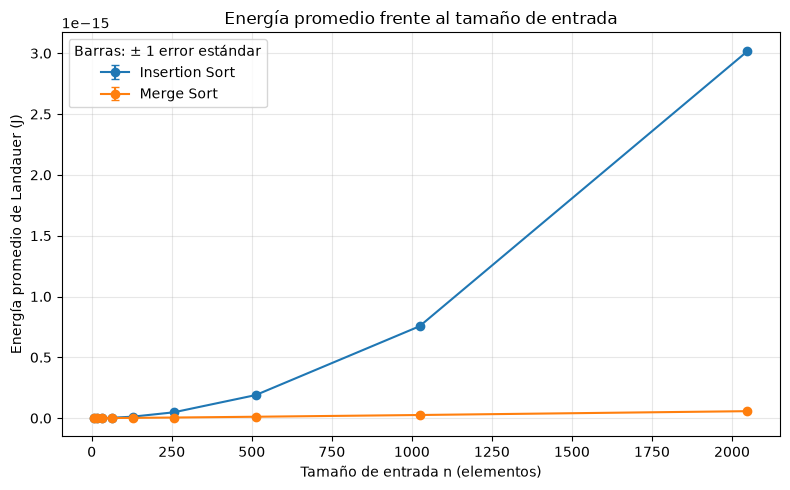

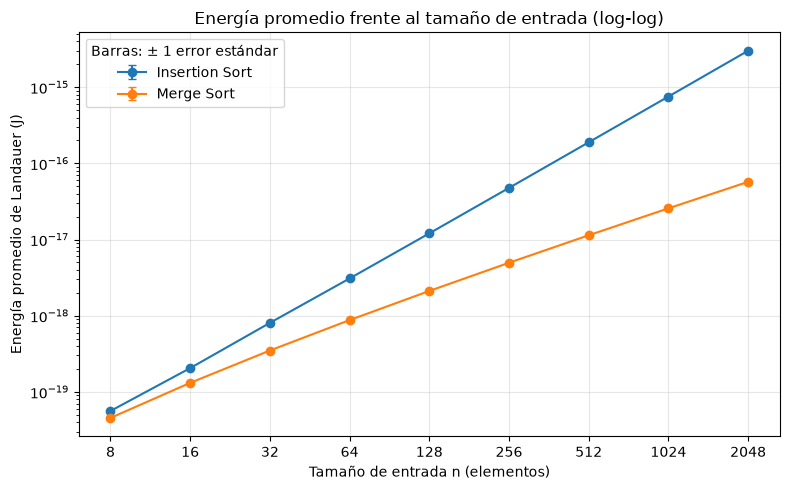

In [21]:
# 7.2. Gráfica de energía promedio frente al tamaño de entrada
def format_n_axis(ax):
    ax.set_xscale("log", base=2)
    ax.set_xticks(N_VALUES, labels=[str(n) for n in N_VALUES])
    ax.set_xlabel("Tamaño de entrada n (elementos)")
    ax.grid(True, alpha=0.3)

for log_scale in (False, True):
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in ALGORITHMS:
        group = summary[summary["algorithm"] == name].sort_values("n")
        ax.errorbar(group["n"], group["mean_energy"], yerr=group["se_energy"],
                    marker="o", capsize=3, label=name)
    if log_scale:
        format_n_axis(ax)
        ax.set_yscale("log")
    ax.set_xlabel("Tamaño de entrada n (elementos)")
    ax.set_ylabel("Energía promedio de Landauer (J)")
    ax.set_title("Energía promedio frente al tamaño de entrada" + (" (log-log)" if log_scale else ""))
    ax.legend(title="Barras: ± 1 error estándar")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


### 7.3. Interpretación de la gráfica

### 7.4. Relación energética

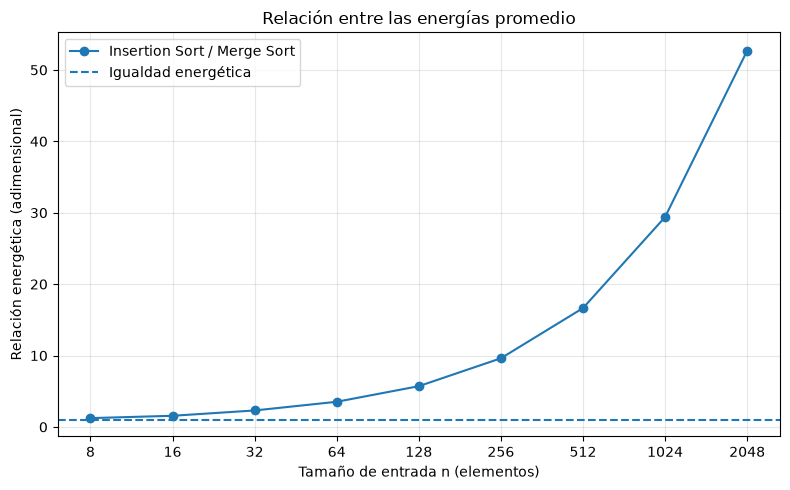

,Relación energética
n,
8,1.233
16,1.562
32,2.307
64,3.523
128,5.708
256,9.615
512,16.642
1024,29.396
2048,52.693


In [16]:
# 7.5. Gráfica de relación energética
energy_by_algorithm = summary.pivot(index="n", columns="algorithm", values="mean_energy")
energy_ratio = energy_by_algorithm["Insertion Sort"] / energy_by_algorithm["Merge Sort"]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(energy_ratio.index, energy_ratio, marker="o", label="Insertion Sort / Merge Sort")
ax.axhline(1, linestyle="--", label="Igualdad energética")
format_n_axis(ax)
ax.set_ylabel("Relación energética (adimensional)")
ax.set_title("Relación entre las energías promedio")
ax.legend()
fig.tight_layout()
plt.show()
display(energy_ratio.rename("Relación energética").to_frame().style.format("{:.3f}"))


### 7.6. Interpretación de la relación energética

## 8. Validación

### 8.1. Validación de Insertion Sort

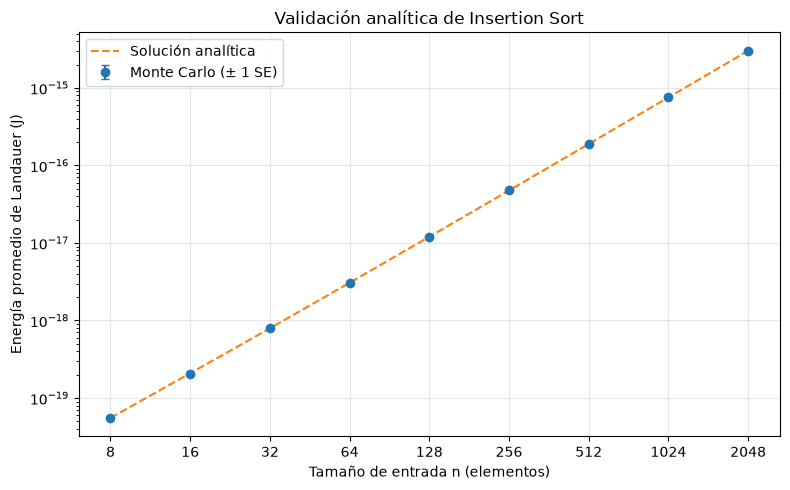

,n,Simulación (J),Teoría (J),Error relativo (%),Diferencia / SE
0,8,5.60128e-20,5.53586e-20,1.182,0.66
2,16,2.04902e-19,2.08488e-19,1.720,1.13
4,32,8.04621e-19,7.92222e-19,1.565,1.36
6,64,3.08263e-18,3.06407e-18,0.606,0.69
8,128,1.20577e-17,1.20195e-17,0.317,0.56
10,256,4.76475e-17,4.75718e-17,0.159,0.37
12,512,1.89354e-16,1.89235e-16,0.062,0.23
14,1024,7.55226e-16,7.54793e-16,0.057,0.30
16,2048,3.01627e-15,3.01483e-15,0.048,0.31


In [17]:
# 8.2. Comparación analítica de Insertion Sort
def harmonic_number(n):
    return math.fsum(1 / i for i in range(1, n + 1))

def insertion_expected_comparisons(n):
    return n * (n - 1) / 4 + n - harmonic_number(n)

validation_i = summary[summary["algorithm"] == "Insertion Sort"].copy().sort_values("n")
validation_i["theoretical_bits"] = validation_i["n"].map(insertion_expected_comparisons)
validation_i["theoretical_energy"] = calculate_energy(validation_i["theoretical_bits"])
validation_i["relative_error_pct"] = 100 * ((validation_i["mean_energy"] - validation_i["theoretical_energy"]).abs() / validation_i["theoretical_energy"])
validation_i["difference_in_se"] = ((validation_i["mean_energy"] - validation_i["theoretical_energy"]).abs() / validation_i["se_energy"].replace(0, np.nan))
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(validation_i["n"], validation_i["mean_energy"], yerr=validation_i["se_energy"],
            fmt="o", capsize=3, label="Monte Carlo (± 1 SE)")
ax.plot(validation_i["n"], validation_i["theoretical_energy"], linestyle="--", label="Solución analítica")
format_n_axis(ax)
ax.set_yscale("log")
ax.set_ylabel("Energía promedio de Landauer (J)")
ax.set_title("Validación analítica de Insertion Sort")
ax.legend()
fig.tight_layout()
plt.show()
display(validation_i[["n", "mean_energy", "theoretical_energy", "relative_error_pct", "difference_in_se"]]
        .rename(columns={"mean_energy": "Simulación (J)", "theoretical_energy": "Teoría (J)",
                         "relative_error_pct": "Error relativo (%)", "difference_in_se": "Diferencia / SE"})
        .style.format({"Simulación (J)": "{:.5e}", "Teoría (J)": "{:.5e}",
                       "Error relativo (%)": "{:.3f}", "Diferencia / SE": "{:.2f}"}))


### 8.3. Interpretación

### 8.4. Validación de Merge Sort

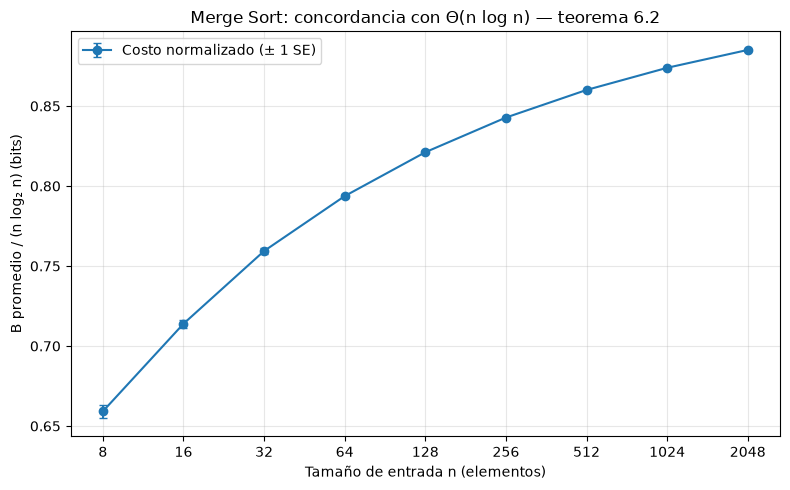

,n,normalized_bits,normalized_se
1,8,0.65917,0.00420
3,16,0.71391,0.00263
5,32,0.75938,0.00195
7,64,0.79370,0.00104
9,128,0.82112,0.00072
11,256,0.84279,0.00043
13,512,0.86003,0.00026
15,1024,0.87388,0.00016
17,2048,0.88505,0.00012


In [18]:
# 8.5. Comparación con el teorema 6.2
validation_m = summary[summary["algorithm"] == "Merge Sort"].copy().sort_values("n")
normalizer = validation_m["n"] * np.log2(validation_m["n"])
validation_m["normalized_bits"] = validation_m["mean_bits"] / normalizer
validation_m["normalized_se"] = (validation_m["se_energy"] / q_L) / normalizer
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(validation_m["n"], validation_m["normalized_bits"], yerr=validation_m["normalized_se"],
            marker="o", capsize=3, label="Costo normalizado (± 1 SE)")
format_n_axis(ax)
ax.set_ylabel("B promedio / (n log₂ n) (bits)")
ax.set_title("Merge Sort: concordancia con Θ(n log n) — teorema 6.2")
ax.legend()
fig.tight_layout()
plt.show()
display(validation_m[["n", "normalized_bits", "normalized_se"]].style.format({
    "normalized_bits": "{:.5f}", "normalized_se": "{:.5f}"}))


### 8.6. Interpretación

### 8.7. Cota inferior energética

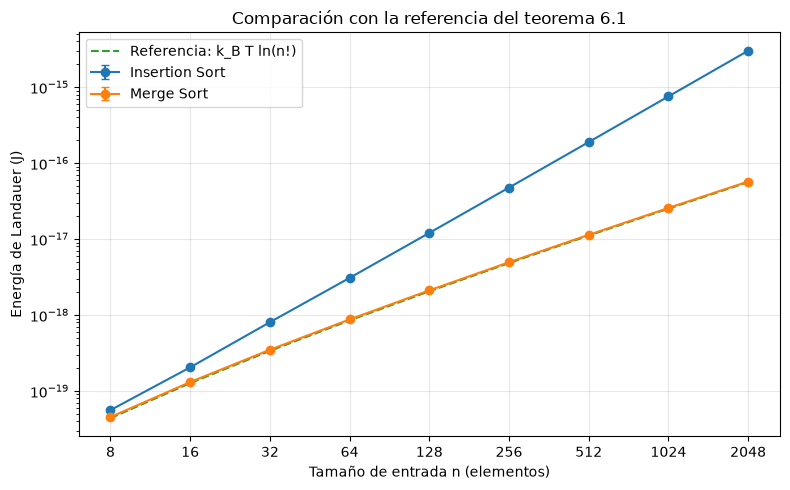

,n,Algoritmo,Promedio (J),Referencia (J),Promedio / referencia
0,8,Insertion Sort,5.6013e-20,4.3924e-20,1.275
1,8,Merge Sort,4.5419e-20,4.3924e-20,1.034
2,16,Insertion Sort,2.0490e-19,1.2704e-19,1.613
3,16,Merge Sort,1.3118e-19,1.2704e-19,1.033
4,32,Insertion Sort,8.0462e-19,3.3781e-19,2.382
5,32,Merge Sort,3.4882e-19,3.3781e-19,1.033
6,64,Insertion Sort,3.0826e-18,8.4980e-19,3.627
7,64,Merge Sort,8.7502e-19,8.4980e-19,1.030
8,128,Insertion Sort,1.2058e-17,2.0561e-18,5.864
9,128,Merge Sort,2.1122e-18,2.0561e-18,1.027


In [19]:
# 8.8. Comparación con la referencia informacional del teorema 6.1
def lower_bound_energy(n):
    # lgamma(n + 1) = ln(n!) sin calcular directamente el factorial.
    return k_B * T * math.lgamma(n + 1)

bound = pd.DataFrame({"n": N_VALUES})
bound["lower_bound"] = bound["n"].map(lower_bound_energy)
comparison_bound = summary.merge(bound, on="n")
comparison_bound["ratio_to_bound"] = comparison_bound["mean_energy"] / comparison_bound["lower_bound"]
fig, ax = plt.subplots(figsize=(8, 5))
for name in ALGORITHMS:
    group = comparison_bound[comparison_bound["algorithm"] == name].sort_values("n")
    ax.errorbar(group["n"], group["mean_energy"], yerr=group["se_energy"],
                marker="o", capsize=3, label=name)
ax.plot(bound["n"], bound["lower_bound"], linestyle="--", label="Referencia: k_B T ln(n!)")
format_n_axis(ax)
ax.set_yscale("log")
ax.set_ylabel("Energía de Landauer (J)")
ax.set_title("Comparación con la referencia del teorema 6.1")
ax.legend()
fig.tight_layout()
plt.show()
display(comparison_bound[["n", "algorithm", "mean_energy", "lower_bound", "ratio_to_bound"]]
        .rename(columns={"algorithm": "Algoritmo", "mean_energy": "Promedio (J)",
                         "lower_bound": "Referencia (J)", "ratio_to_bound": "Promedio / referencia"})
        .style.format({"Promedio (J)": "{:.4e}", "Referencia (J)": "{:.4e}",
                       "Promedio / referencia": "{:.3f}"}))


### 8.9. Interpretación

### 8.10. Confiabilidad de Monte Carlo

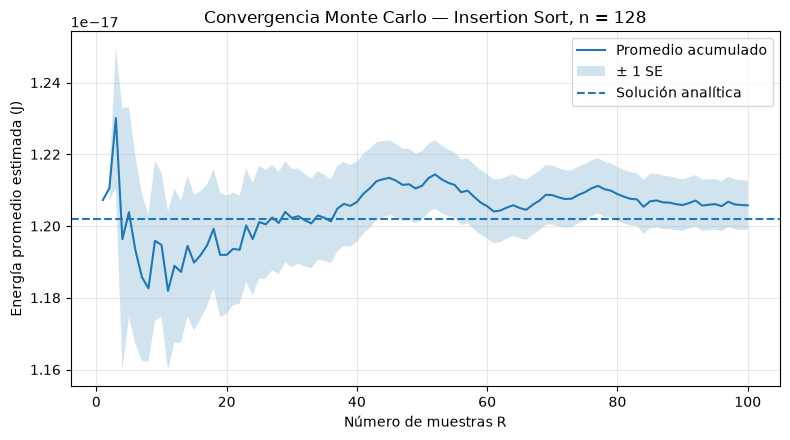

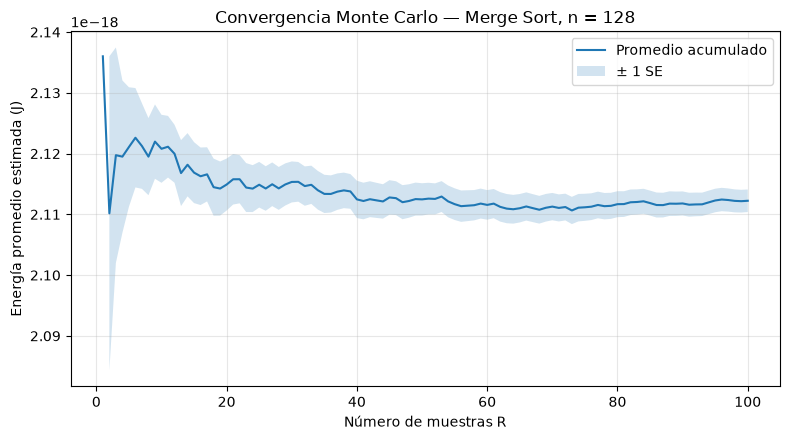

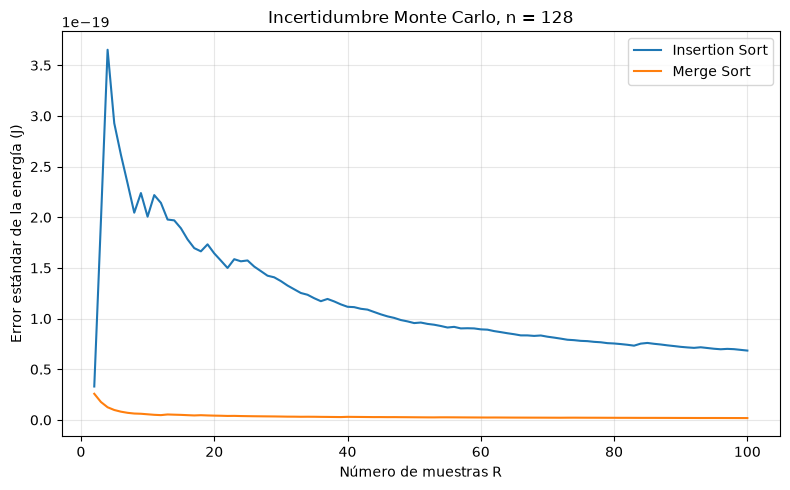

,algorithm,repetition,running_mean,running_se,relative_se_pct
998,Insertion Sort,100,1.2058e-17,6.8470e-20,0.568
999,Merge Sort,100,2.1122e-18,1.8557e-21,0.088


In [20]:
# 8.11. Análisis de convergencia de Monte Carlo
n_convergence = 128 if 128 in N_VALUES else N_VALUES[len(N_VALUES) // 2]
convergence = results[results["n"] == n_convergence].copy().sort_values(["algorithm", "repetition"])
convergence["running_mean"] = convergence.groupby("algorithm")["energy"].transform(lambda x: x.expanding().mean())
convergence["running_se"] = convergence.groupby("algorithm")["energy"].transform(
    lambda x: x.expanding(min_periods=2).std() / np.sqrt(np.arange(1, len(x) + 1)))

for name in ALGORITHMS:
    group = convergence[convergence["algorithm"] == name]
    r = group["repetition"].to_numpy()
    mean = group["running_mean"].to_numpy()
    se = group["running_se"].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(r, mean, label="Promedio acumulado")
    ax.fill_between(r, mean - se, mean + se, alpha=0.2, label="± 1 SE")
    if name == "Insertion Sort":
        ax.axhline(calculate_energy(insertion_expected_comparisons(n_convergence)),
                   linestyle="--", label="Solución analítica")
    ax.set_xlabel("Número de muestras R")
    ax.set_ylabel("Energía promedio estimada (J)")
    ax.set_title(f"Convergencia Monte Carlo — {name}, n = {n_convergence}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name in ALGORITHMS:
    group = convergence[convergence["algorithm"] == name]
    ax.plot(group["repetition"], group["running_se"], label=name)
ax.set_xlabel("Número de muestras R")
ax.set_ylabel("Error estándar de la energía (J)")
ax.set_title(f"Incertidumbre Monte Carlo, n = {n_convergence}")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

final_precision = convergence.groupby("algorithm").tail(1).copy()
final_precision["relative_se_pct"] = 100 * final_precision["running_se"] / final_precision["running_mean"]
display(final_precision[["algorithm", "repetition", "running_mean", "running_se", "relative_se_pct"]]
        .style.format({"running_mean": "{:.4e}", "running_se": "{:.4e}", "relative_se_pct": "{:.3f}"}))


### 8.12. Conclusión de la validación

## 9. Limitaciones

## 10. Conclusiones y conexión con ISC

## 11. Referencias y declaración de uso de IA

### 11.1. Referencias bibliográficas

### 11.2. Declaración de uso de inteligencia artificial